# Experiment 000: Image representation

## Objective

Understand how digital images are represented numerically in Python before using them as inouts to a nerural network.

## Questions
- How is an image represented in memory?
- What does each image dimension represent?
- What numerical values are stored in individual pixels?
- How are red, green, and blue channels separated?

In [135]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

In [136]:
data_dir = Path("../data/raw/shipsnet")

image_path = next(data_dir.glob("*.png"))

print(image_path)

..\data\raw\shipsnet\0__20150718_184300_090b__-122.35324421973536_37.772113980272394.png


<PIL.PngImagePlugin.PngImageFile image mode=RGB size=80x80 at 0x21E1CE7B390>
Size: (80, 80)
Mode: RGB


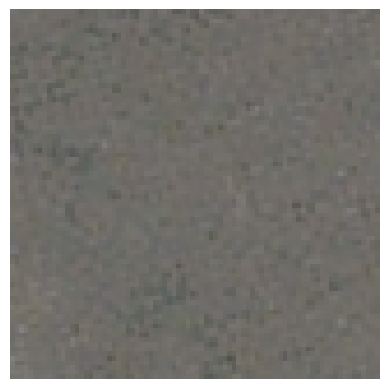

In [137]:
image = Image.open(image_path)

print(image)
print("Size:", image.size)
print("Mode:", image.mode)

plt.imshow(image)
plt.axis("off")
plt.show()

In [138]:
image_array = np.array(image)

print("Array shape:", image_array.shape)
print("Data type:", image_array.dtype)

pixel = image_array[0, 0]
print("Top-left pixel:", pixel)

Array shape: (80, 80, 3)
Data type: uint8
Top-left pixel: [116 114 109]


In [139]:
red_channel = image_array[:, :, 0]
green_channel = image_array[:, :, 1]
blue_channel = image_array[:, :, 2]

print("Red shape", red_channel.shape)
print("Green shape", green_channel.shape)
print("Blue shape", blue_channel.shape)



Red shape (80, 80)
Green shape (80, 80)
Blue shape (80, 80)


[[116 114 109 109 111]
 [111 111 111 111 114]
 [110 113 115 115 114]
 [110 110 112 115 110]
 [109 107 110 113 111]]


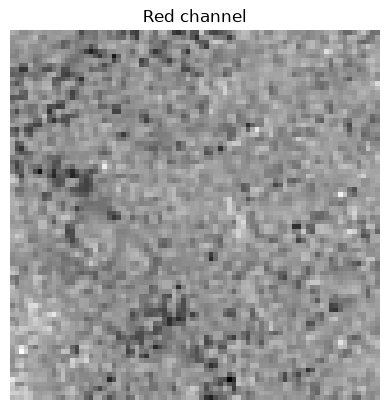

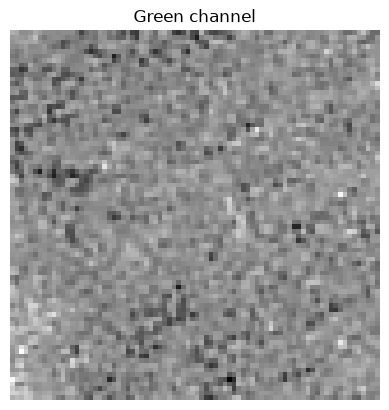

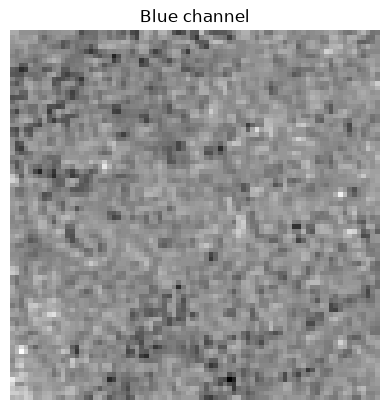

In [140]:
print(red_channel[:5, :5])
plt.imshow(red_channel, cmap="gray")
plt.title("Red channel")
plt.axis("off")
plt.show()

plt.imshow(green_channel, cmap="gray")
plt.title("Green channel")
plt.axis("off")
plt.show()

plt.imshow(blue_channel, cmap="gray")
plt.title("Blue channel")
plt.axis("off")
plt.show()

## Inturpretation 

A ShipsNet image is represented as an 80x80x3 numerical array.
The first two dimensions identity the locaion of a pixel in the image, while the third dimension contains its RGB intensity values.
Each RGB channel cna be represented independently as an 80x80 matrix. Togetherm the three matrices contain 19,200 numerical values that completely describe the image.

In [141]:
row = 10
col = 10

print("Red:", red_channel[row, col])
print("Green:", green_channel[row, col])
print("Blue:", blue_channel[row, col])
print("Original RGB pixel:", image_array[row, col])
print("Number of values:", image_array.size)

Red: 97
Green: 95
Blue: 90
Original RGB pixel: [97 95 90]
Number of values: 19200


In [142]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

PyTorch version: 2.13.0+cu130
CUDA available: True
GPU NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [143]:
image_tensor = torch.from_numpy(image_array)

print("Tensor shape:", image_tensor.shape)
print("Tensor dtype:", image_tensor.dtype)

Tensor shape: torch.Size([80, 80, 3])
Tensor dtype: torch.uint8


In [144]:
image_tensor = image_tensor.permute(2, 0, 1)

print("Reorderd tensor shape:", image_tensor.shape)



Reorderd tensor shape: torch.Size([3, 80, 80])


In [145]:
print("dtype:", image_tensor.dtype)
print("min:", image_tensor.min())
print("max:", image_tensor.max())

dtype: torch.uint8
min: tensor(75, dtype=torch.uint8)
max: tensor(133, dtype=torch.uint8)


In [146]:
image_tensor = image_tensor.float()
print("dtype:", image_tensor.dtype)

image_tensor = image_tensor / 255.0

print("min:", image_tensor.min())
print("max:", image_tensor.max())
print(image_tensor.shape)

dtype: torch.float32
min: tensor(0.2941)
max: tensor(0.5216)
torch.Size([3, 80, 80])


In [147]:
batched_image = image_tensor.unsqueeze(0)
print(batched_image.shape)

torch.Size([1, 3, 80, 80])


In [148]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [149]:
batched_image = batched_image.to(device)
print(batched_image.device)

cuda:0


In [150]:
import torch.nn as nn

In [151]:
conv = nn.Conv2d(
    in_channels=3,
    out_channels=8,
    kernel_size=3,
    padding=1
)
conv = conv.to(device)

print(conv)
print("Weight shape:", conv.weight.shape)
print("Bias shape:", conv.bias.shape)


Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
Weight shape: torch.Size([8, 3, 3, 3])
Bias shape: torch.Size([8])


In [152]:
feature_maps = conv(batched_image)
print("Input shape:", batched_image.shape)
print("Output shape:", feature_maps.shape)

Input shape: torch.Size([1, 3, 80, 80])
Output shape: torch.Size([1, 8, 80, 80])


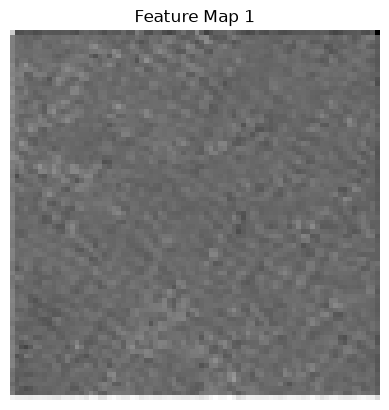

In [153]:
first_feature_map = feature_maps[0, 0].detach().cpu().numpy()

plt.imshow(first_feature_map, cmap="grey")
plt.title("Feature Map 1")
plt.axis("off")
plt.show()

In [154]:
row = 10
col = 10

patch = batched_image[
    0,
    :,
    row - 1:row + 2,
    col - 1:col + 2
]
print("Patch shape:", patch.shape)
print(patch)

Patch shape: torch.Size([3, 3, 3])
tensor([[[0.4549, 0.4196, 0.3725],
         [0.3922, 0.3804, 0.3843],
         [0.3922, 0.4000, 0.4392]],

        [[0.4392, 0.4157, 0.3804],
         [0.3804, 0.3725, 0.3843],
         [0.3804, 0.3922, 0.4314]],

        [[0.4235, 0.3961, 0.3569],
         [0.3647, 0.3529, 0.3569],
         [0.3608, 0.3686, 0.4039]]], device='cuda:0')


In [155]:
filter_weights = conv.weight[0]
filter_bias = conv.bias[0]
print("Filter shape:", filter_weights.shape)
print("Bias:", filter_bias)

Filter shape: torch.Size([3, 3, 3])
Bias: tensor(0.1376, device='cuda:0', grad_fn=<SelectBackward0>)


In [156]:
manual_value = (patch * filter_weights).sum() + filter_bias

print("Manual calculation:", manual_value)

Manual calculation: tensor(0.0228, device='cuda:0', grad_fn=<AddBackward0>)


In [157]:
pytorch_value = feature_maps[0, 0, row, col]

print("PyTorch Conv2d:", pytorch_value)
print("Manual result:", manual_value)
print(torch.allclose(manual_value, pytorch_value))

PyTorch Conv2d: tensor(0.0228, device='cuda:0', grad_fn=<SelectBackward0>)
Manual result: tensor(0.0228, device='cuda:0', grad_fn=<AddBackward0>)
True


In [158]:
relu = nn.ReLU()
activated_maps = relu(feature_maps)

print("Before ReLU")
print(f"Min: {feature_maps.min().item()}")
print(f"Max: {feature_maps.max().item()}")

print(f"After ReLU")
print(f"Min: {activated_maps.min().item()}")
print(f"Max: {activated_maps.max().item()}")

Before ReLU
Min: -0.5728009343147278
Max: 0.7012990713119507
After ReLU
Min: 0.0
Max: 0.7012990713119507


In [159]:
negative_before = (feature_maps < 0).sum()
negative_after = (activated_maps < 0).sum()

print(f"Negative values before ReLU: {negative_before.item()}")
print(f"Negative values after ReLU {negative_after.item()}")

Negative values before ReLU: 30183
Negative values after ReLU 0


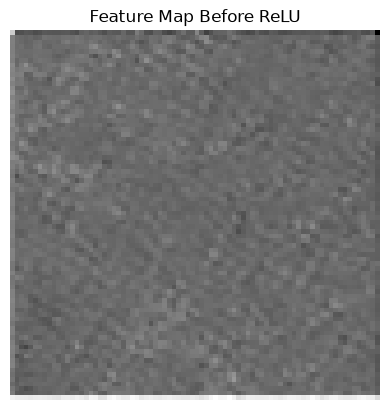

<function matplotlib.pyplot.show(close=None, block=None)>

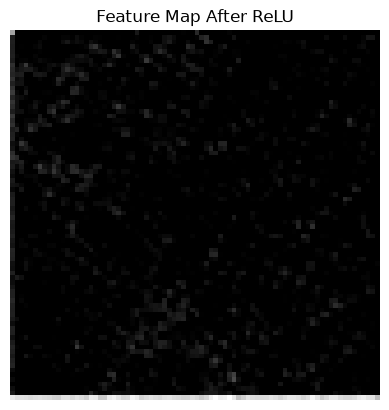

In [160]:
before_relu = feature_maps[0,0].detach().cpu().numpy()
after_relu = activated_maps[0,0].detach().cpu().numpy()

plt.imshow(before_relu, cmap="grey")
plt.title("Feature Map Before ReLU")
plt.axis("off")
plt.show()

plt.imshow(after_relu, cmap="grey")
plt.title("Feature Map After ReLU")
plt.axis("off")
plt.show

In [161]:
pool = nn.MaxPool2d(kernel_size=2, stride=2)

pooled_maps = pool(activated_maps)

print(f"Before pooling: {activated_maps.shape}")
print(f"After pooling: {pooled_maps.shape}")

Before pooling: torch.Size([1, 8, 80, 80])
After pooling: torch.Size([1, 8, 40, 40])


In [162]:
region = activated_maps[0, 0, 0:2, 0:2]

print("2x2 region:")
print(region)

print(f"\nMaximum value: {region.max().item()}")
print(f"Pooling output: {pooled_maps[0, 0, 0, 0].item()}")

2x2 region:
tensor([[0.0893, 0.0000],
        [0.0156, 0.0000]], device='cuda:0', grad_fn=<SliceBackward0>)

Maximum value: 0.08931596577167511
Pooling output: 0.08931596577167511


In [163]:
model = nn.Sequential(
    nn.Conv2d(
        in_channels=3, 
        out_channels=8,
        kernel_size=3,
        padding=1
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Conv2d(
        in_channels=8,
        out_channels=16,
        kernel_size=3,
        padding=1
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),
    nn.Flatten(),

    nn.Linear(
        in_features=16 * 20 * 20,
        out_features=2
    )
)
model = model.to(device)

print(model)

Sequential(
  (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=6400, out_features=2, bias=True)
)


In [164]:
output = model(batched_image)

print(f"Input shape: {batched_image.shape}")
print(f"Output shape: {output.shape}")
print(f"Output: {output}")

Input shape: torch.Size([1, 3, 80, 80])
Output shape: torch.Size([1, 2])
Output: tensor([[-0.0938, -0.0288]], device='cuda:0', grad_fn=<AddmmBackward0>)


In [165]:
x = batched_image
print(f"Input: {x.shape}")

for i, layer in enumerate(model):
    x = layer(x)
    print(f"After layer {i} ({layer.__class__.__name__}): {x.shape}")

Input: torch.Size([1, 3, 80, 80])
After layer 0 (Conv2d): torch.Size([1, 8, 80, 80])
After layer 1 (ReLU): torch.Size([1, 8, 80, 80])
After layer 2 (MaxPool2d): torch.Size([1, 8, 40, 40])
After layer 3 (Conv2d): torch.Size([1, 16, 40, 40])
After layer 4 (ReLU): torch.Size([1, 16, 40, 40])
After layer 5 (MaxPool2d): torch.Size([1, 16, 20, 20])
After layer 6 (Flatten): torch.Size([1, 6400])
After layer 7 (Linear): torch.Size([1, 2])


In [166]:
total_trainable_params = sum(p.numel() for p in model.parameters())

print(f"Total trainable parameters: {total_trainable_params}")

Total trainable parameters: 14194


In [167]:
for name, parameter in model.named_parameters():
    print(f"{name}: {parameter.shape} -> {parameter.numel()} parameters")

0.weight: torch.Size([8, 3, 3, 3]) -> 216 parameters
0.bias: torch.Size([8]) -> 8 parameters
3.weight: torch.Size([16, 8, 3, 3]) -> 1152 parameters
3.bias: torch.Size([16]) -> 16 parameters
7.weight: torch.Size([2, 6400]) -> 12800 parameters
7.bias: torch.Size([2]) -> 2 parameters


In [168]:
label_value = int(image_path.name.split("__")[0])

print(f"Finlename: {image_path.name}")
print(f"Label: {label_value}")

Finlename: 0__20150718_184300_090b__-122.35324421973536_37.772113980272394.png
Label: 0


In [169]:
target = torch.tensor([label_value], dtype=torch.long, device=device)

print(f"Target: {target}")
print(f"Target shape: {target.shape}")

Target: tensor([0], device='cuda:0')
Target shape: torch.Size([1])


In [170]:
criterion = nn.CrossEntropyLoss()
output = model(batched_image)
loss = criterion(output, target)

print(f"Raw model output: {output}")
print(f"Correct Class: {target.item()}")
print(f"Loss: {loss.item()}")

Raw model output: tensor([[-0.0938, -0.0288]], device='cuda:0', grad_fn=<AddmmBackward0>)
Correct Class: 0
Loss: 0.7261598110198975


In [171]:
loss.backward()
print(model[0].weight.grad)

tensor([[[[ 0.0205,  0.0208,  0.0185],
          [ 0.0181,  0.0187,  0.0175],
          [ 0.0173,  0.0189,  0.0194]],

         [[ 0.0200,  0.0203,  0.0178],
          [ 0.0177,  0.0180,  0.0170],
          [ 0.0173,  0.0186,  0.0189]],

         [[ 0.0187,  0.0190,  0.0170],
          [ 0.0166,  0.0169,  0.0161],
          [ 0.0166,  0.0174,  0.0175]]],


        [[[ 0.0191,  0.0170,  0.0172],
          [ 0.0193,  0.0182,  0.0178],
          [ 0.0178,  0.0170,  0.0170]],

         [[ 0.0179,  0.0158,  0.0162],
          [ 0.0179,  0.0167,  0.0165],
          [ 0.0164,  0.0155,  0.0160]],

         [[ 0.0176,  0.0155,  0.0155],
          [ 0.0178,  0.0168,  0.0163],
          [ 0.0165,  0.0155,  0.0161]]],


        [[[ 0.0000,  0.0000,  0.0000],
          [ 0.0000,  0.0000,  0.0000],
          [ 0.0000,  0.0000,  0.0000]],

         [[ 0.0000,  0.0000,  0.0000],
          [ 0.0000,  0.0000,  0.0000],
          [ 0.0000,  0.0000,  0.0000]],

         [[ 0.0000,  0.0000,  0.0000],
     

In [172]:
grad = model[0].weight.grad

print(f"Gradoemt shape: {grad.shape}")
print(f"Gradient mean: {grad.mean().item()}")
print(f"Gradient min: {grad.min().item()}")
print(f"Gradient max: {grad.max().item()}")

Gradoemt shape: torch.Size([8, 3, 3, 3])
Gradient mean: 0.00532090337947011
Gradient min: -0.0034631481394171715
Gradient max: 0.02080206759274006


In [173]:
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

weight_before = model[0].weight[0, 0, 0, 0].item()
print(f"Weight before update: {weight_before}")

optimizer.step()

weight_after = model[0].weight[0, 0, 0, 0].item()
print(f"Weight after update: {weight_after}")

Weight before update: 0.1635848432779312
Weight after update: 0.16337953507900238


In [174]:
optimizer.zero_grad()

print(model[0].weight.grad)

None


In [175]:
for step in range(10):
    optimizer.zero_grad()

    output = model(batched_image)
    loss = criterion(output, target)

    loss.backward()
    optimizer.step()

    print(f"Step {step + 1}: loss = {loss.item():.4f}")

Step 1: loss = 0.5775
Step 2: loss = 0.4626
Step 3: loss = 0.3582
Step 4: loss = 0.2655
Step 5: loss = 0.1907
Step 6: loss = 0.1363
Step 7: loss = 0.0993
Step 8: loss = 0.0746
Step 9: loss = 0.0578
Step 10: loss = 0.0462


In [176]:
output = model(batched_image)
print(f"Logits: {output}")

Logits: tensor([[ 1.5138, -1.7414]], device='cuda:0', grad_fn=<AddmmBackward0>)


In [177]:
probabilities = torch.softmax(output, dim=1)

print(f"Probabilities: {probabilities}")

Probabilities: tensor([[0.9629, 0.0371]], device='cuda:0', grad_fn=<SoftmaxBackward0>)


In [178]:
predicted_class = output.argmax(dim=1)

print(f"True class: {target.item()}")
print(f"Predicted class: {predicted_class.item()}")

True class: 0
Predicted class: 0


In [179]:
from torch.utils.data import Dataset, DataLoader

In [180]:
class ShipsNetDataset(Dataset):
    def __init__(self, data_dir):
        self.data_dir = Path(data_dir)
        self.image_paths = sorted(self.data_dir.glob("*.png"))

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image_path = self.image_paths[index]

        image = Image.open(image_path).convert("RGB")
        image_array = np.array(image)

        image_tensor = torch.from_numpy(image_array)
        image_tensor = image_tensor.permute(2, 0, 1)
        image_tensor = image_tensor.float() / 255.0

        label = int(image_path.name.split("__")[0])
        label_tensor = torch.tensor(label, dtype=torch.long)

        return image_tensor, label_tensor

In [181]:
dataset = ShipsNetDataset("../data/raw/shipsnet")

print(f"Dataset size: {len(dataset)}")

Dataset size: 4000


In [182]:
sample_image, sample_label = dataset[0]

print(f"Image shape: {sample_image.shape}")
print(f"Label: {sample_label.item()}")
print(f"Data type: {sample_image.dtype}")
print(f"Min value: {sample_image.min().item()}")
print(f"Max value: {sample_image.max().item()}")

Image shape: torch.Size([3, 80, 80])
Label: 0
Data type: torch.float32
Min value: 0.29411765933036804
Max value: 0.5215686559677124


In [183]:
loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

In [184]:
images, labels = next(iter(loader))

print(f"Image batch shape: {images.shape}")
print(f"Label batch shape: {labels.shape}")

Image batch shape: torch.Size([32, 3, 80, 80])
Label batch shape: torch.Size([32])


In [198]:
scene_ids = []

for image_path in dataset.image_paths:
    parts = image_path.name.split("__")
    scene_id = parts[1]
    scene_ids.append(scene_id)

print(f" Total images: {len(scene_ids)}")
print(f"Unique scenes: {len(set(scene_ids))}")

 Total images: 4000
Unique scenes: 434


In [199]:
from collections import Counter

scene_counts = Counter(scene_ids)


In [200]:
scene_labels = {}

for image_path in dataset.image_paths:
    parts = image_path.name.split("__")

    label = int(parts[0])
    scene_id = parts[1]

    if scene_id not in scene_labels:
        scene_labels[scene_id] = []
    scene_labels[scene_id].append(label)

for scene_id, labels in scene_labels.items():
    ship_count = sum(labels)
    no_ship_count = len(labels) - ship_count

In [201]:
scene_summary = []

for scene_id, labels in scene_labels.items():
    ship_count = sum(labels)
    no_ship_count = len(labels) - ship_count
    total_count = len(labels)

    scene_summary.append(
        (scene_id, ship_count, no_ship_count, total_count)
    )
scene_summary.sort(key=lambda x:[3], reverse=True)

In [202]:
print(f"Unique scenes: {len(scene_summary)}")

scene_with_ships = sum(
    1 for _, ship_count, _, _ in scene_summary
    if ship_count > 0
)

print(f"Scenes containing ships: {scene_with_ships}")
print(
    f"Scenes containing no ships: "
    f"{len(scene_summary) - scene_with_ships}"
)

Unique scenes: 434
Scenes containing ships: 214
Scenes containing no ships: 220


In [203]:
scene_sizes = [total for _, _, _, total in scene_summary]

print(f"Smallest scene: {min(scene_sizes)} images")
print(f"Largest scene: {max(scene_sizes)} images")
print(
    f"Average images per scens: "
    f"{sum(scene_sizes) / len(scene_sizes):.2f}"
)

Smallest scene: 1 images
Largest scene: 39 images
Average images per scens: 9.22
